# 4. European Option Pricing by Monte Carlo

*Part 4 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

Notebook 3 estimated *expected payoffs* under the real-world drift $\mu$. An expected payoff is not a price: it ignores the time value of money and the investor's attitude to risk. **Risk-neutral pricing** resolves both issues.

### Risk-neutral valuation

In the Black–Scholes market (GBM stock, constant risk-free rate $r$), an option can be replicated by continuously rebalancing a portfolio of stock and cash, so by no-arbitrage its price is the cost of that portfolio. That cost turns out to equal a discounted expectation under an artificial probability measure $\mathbb{Q}$, the **risk-neutral measure**, under which

$$
dS_t = r\,S_t\,dt + \sigma S_t\,dW^{\mathbb{Q}}_t.
$$

The real-world drift $\mu$ is replaced by $r$, and $\mu$ drops out of the price entirely. Under $\mathbb{Q}$ the discounted stock price $e^{-rt}S_t$ is a martingale.

The price of a European payoff $h(S_T)$ is therefore

$$
V_0 = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\!\left[h(S_T)\right],
\qquad
S_T = S_0 \exp\!\left[\left(r-\tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right].
$$

This is an expectation of a function of a normal variable, so the Monte Carlo machinery of Notebook 3 applies directly:

1. simulate $S_T$ under $\mathbb{Q}$;
2. compute the payoff $h(S_T)$;
3. discount and average.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import (
    black_scholes_price,
    european_payoff,
    price_european_option_mc,
    simulate_gbm_terminal,
    summarise_samples,
)

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
# At-the-money one-year option
initial_price = 100
strike_price = 100
risk_free_rate = 0.05
annual_volatility = 0.20
time_to_maturity = 1

n_simulations = 100_000

## 4.1 Simulating under the risk-neutral measure

In [3]:
terminal_prices = simulate_gbm_terminal(
    initial_price=initial_price,
    drift=risk_free_rate,
    volatility=annual_volatility,
    time_horizon=time_to_maturity,
    n_paths=n_simulations,
    rng=rng
)

discount_factor = np.exp(-risk_free_rate * time_to_maturity)

pd.Series(terminal_prices).describe()

count    100000.000000
mean        105.054866
std          21.324055
min          42.834646
25%          89.969148
50%         102.860062
75%         117.813598
max         280.512204
dtype: float64

A first sanity check of the measure: under $\mathbb{Q}$ the discounted stock is a martingale, so $e^{-rT}\,\mathbb{E}^{\mathbb{Q}}[S_T]$ must equal $S_0$. The stock prices itself correctly.

In [4]:
discounted_stock = summarise_samples(discount_factor * terminal_prices)

pd.Series({
    "MC estimate of exp(-rT) E^Q[S_T]": discounted_stock.estimate,
    "standard_error": discounted_stock.standard_error,
    "S_0": initial_price,
    "S_0 inside 95% CI": discounted_stock.contains(initial_price)
})

MC estimate of exp(-rT) E^Q[S_T]    99.93128
standard_error                      0.064144
S_0                                      100
S_0 inside 95% CI                       True
dtype: object

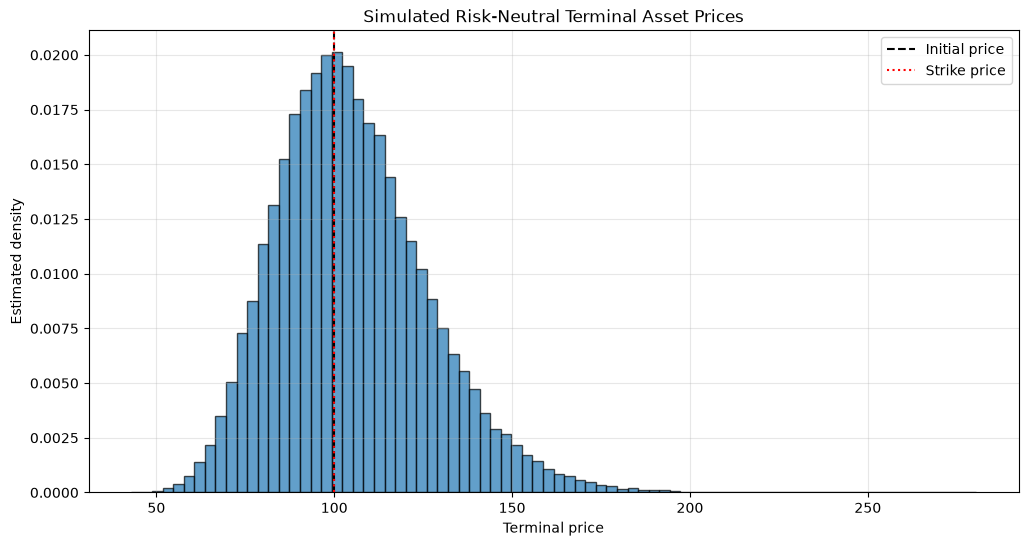

In [5]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    terminal_prices,
    bins=80,
    density=True,
    edgecolor="black",
    alpha=0.7
)

ax.axvline(
    initial_price,
    linestyle="--",
    color="black",
    label="Initial price"
)

ax.axvline(
    strike_price,
    linestyle=":",
    color="red",
    label="Strike price"
)

ax.set_title("Simulated Risk-Neutral Terminal Asset Prices")
ax.set_xlabel("Terminal price")
ax.set_ylabel("Estimated density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

## 4.2 Payoffs

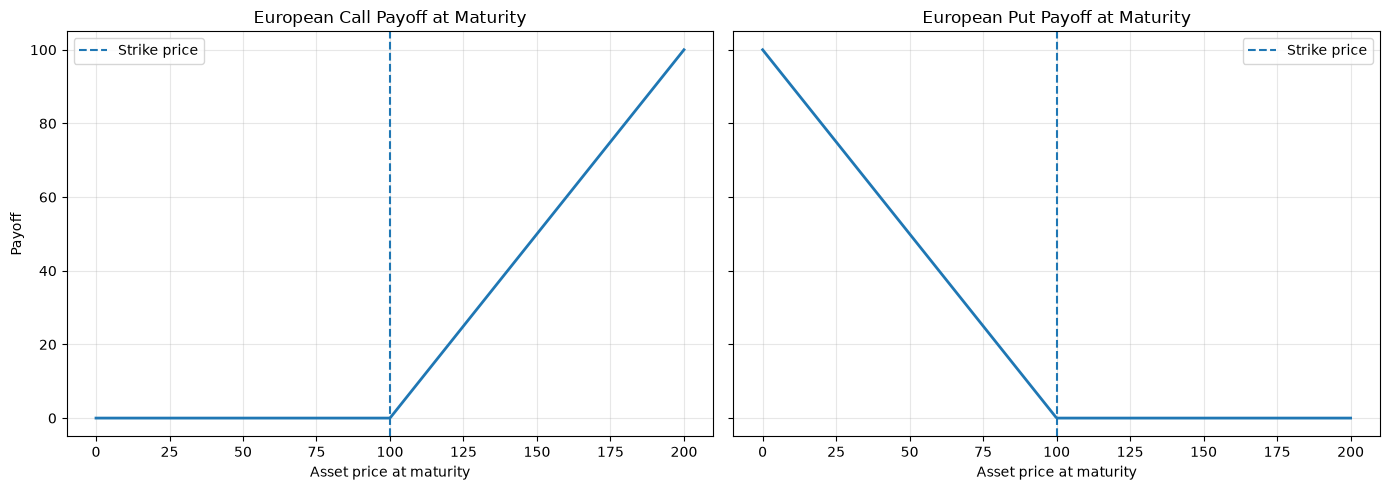

In [6]:
price_grid = np.linspace(0, 2 * strike_price, 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, option_type in zip(axes, ["call", "put"]):
    ax.plot(
        price_grid,
        european_payoff(price_grid, strike_price, option_type),
        linewidth=2
    )
    ax.axvline(strike_price, linestyle="--", label="Strike price")
    ax.set_title(f"European {option_type.title()} Payoff at Maturity")
    ax.set_xlabel("Asset price at maturity")
    ax.legend()
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Payoff")

plt.tight_layout()
plt.show()

## 4.3 Monte Carlo prices

Price = discounted average payoff, with a standard error and a 95% confidence interval from Notebook 3.

In [7]:
call_payoffs = european_payoff(terminal_prices, strike_price, "call")
put_payoffs = european_payoff(terminal_prices, strike_price, "put")

call_mc = summarise_samples(discount_factor * call_payoffs)
put_mc = summarise_samples(discount_factor * put_payoffs)

for name, result in [("Call", call_mc), ("Put", put_mc)]:
    low, high = result.confidence_interval
    print(
        f"{name}: {result.estimate:.4f}  "
        f"(SE {result.standard_error:.4f}, 95% CI [{low:.4f}, {high:.4f}])"
    )

Call: 10.4205  (SE 0.0468, 95% CI [10.3289, 10.5122])
Put: 5.6122  (SE 0.0275, 95% CI [5.5583, 5.6661])


In [8]:
pd.Series({
    "call_probability_in_the_money": np.mean(terminal_prices > strike_price),
    "put_probability_in_the_money": np.mean(terminal_prices < strike_price),
    "mean_call_payoff": call_payoffs.mean(),
    "mean_put_payoff": put_payoffs.mean(),
    "discount_factor": discount_factor
})

call_probability_in_the_money     0.557500
put_probability_in_the_money      0.442500
mean_call_payoff                 10.954814
mean_put_payoff                   5.899948
discount_factor                   0.951229
dtype: float64

## 4.4 Comparison with Black–Scholes

For European options under GBM the risk-neutral expectation has a closed form:

$$
C = S_0\,\Phi(d_1) - K e^{-rT}\Phi(d_2), \qquad
P = K e^{-rT}\Phi(-d_2) - S_0\,\Phi(-d_1),
$$

$$
d_1 = \frac{\ln(S_0/K) + (r + \tfrac12\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}.
$$

(Implemented in `stochmc.black_scholes_price`.)

In [9]:
call_price_bs = black_scholes_price(
    initial_price, strike_price, risk_free_rate, annual_volatility, time_to_maturity, "call"
)
put_price_bs = black_scholes_price(
    initial_price, strike_price, risk_free_rate, annual_volatility, time_to_maturity, "put"
)

price_comparison = pd.DataFrame({
    "Monte Carlo": [call_mc.estimate, put_mc.estimate],
    "Standard error": [call_mc.standard_error, put_mc.standard_error],
    "Black-Scholes": [call_price_bs, put_price_bs],
}, index=["Call", "Put"])

price_comparison["Absolute error"] = np.abs(
    price_comparison["Monte Carlo"] - price_comparison["Black-Scholes"]
)
price_comparison["Error / SE"] = (
    price_comparison["Absolute error"] / price_comparison["Standard error"]
)
price_comparison["BS inside 95% CI"] = [
    call_mc.contains(call_price_bs),
    put_mc.contains(put_price_bs)
]

price_comparison

,Monte Carlo,Standard error,Black-Scholes,Absolute error,Error / SE,BS inside 95% CI
Call,10.420541,0.04677,10.450584,0.030042,0.642344,True
Put,5.612204,0.02752,5.573526,0.038678,1.405440,True


Both Monte Carlo prices lie within two standard errors of the analytical values, so the two methods agree within sampling error.

### Put–call parity

$C - P = S_0 - K e^{-rT}$ holds for any model without arbitrage. Because the call and put estimates here use the **same** simulated prices, and $\max(S-K,0) - \max(K-S,0) = S - K$ pathwise, the parity error equals the martingale error of the discounted stock from §4.1.

In [10]:
pd.Series({
    "Monte Carlo C - P": call_mc.estimate - put_mc.estimate,
    "S0 - K exp(-rT)": initial_price - strike_price * discount_factor,
    "absolute_difference": abs(
        (call_mc.estimate - put_mc.estimate)
        - (initial_price - strike_price * discount_factor)
    ),
    "martingale_error": abs(discounted_stock.estimate - initial_price)
})

Monte Carlo C - P      4.808337
S0 - K exp(-rT)        4.877058
absolute_difference    0.068720
martingale_error       0.068720
dtype: float64

## 4.5 Why $r$ and not $\mu$?

Pricing with the real-world drift $\mu$ looks natural but gives the wrong answer. With $\mu > r$ it inflates call prices, and someone selling calls at that price could hedge them for the cheaper Black–Scholes cost and lock in a riskless profit. Black–Scholes prices do not depend on $\mu$ at all.

In [11]:
drift_values = [0.00, 0.05, 0.10, 0.15]
drift_rows = []

for drift in drift_values:
    real_world_prices = simulate_gbm_terminal(
        initial_price, drift, annual_volatility, time_to_maturity, n_simulations, rng
    )
    naive_call = summarise_samples(
        discount_factor * european_payoff(real_world_prices, strike_price, "call")
    )

    drift_rows.append({
        "simulation_drift": drift,
        "discounted_mean_call_payoff": naive_call.estimate,
        "standard_error": naive_call.standard_error,
        "black_scholes_price": call_price_bs
    })

pd.DataFrame(drift_rows).set_index("simulation_drift")

,discounted_mean_call_payoff,standard_error,black_scholes_price
simulation_drift,,,
0.00,7.626327,0.039919,10.450584
0.05,10.439174,0.046570,10.450584
0.10,13.950348,0.053430,10.450584
0.15,18.048485,0.060358,10.450584


Only the simulation with drift $r = 5\%$ reproduces the arbitrage-free price. The real-world drift affects the *probability* of the option ending in the money but not its *price*.

## 4.6 Pricing across strikes

The same simulation gives prices for any strike at no extra simulation cost, because only the payoff changes. Error bars are 95% confidence intervals; they are too small to see at this scale, so the absolute errors are shown separately.

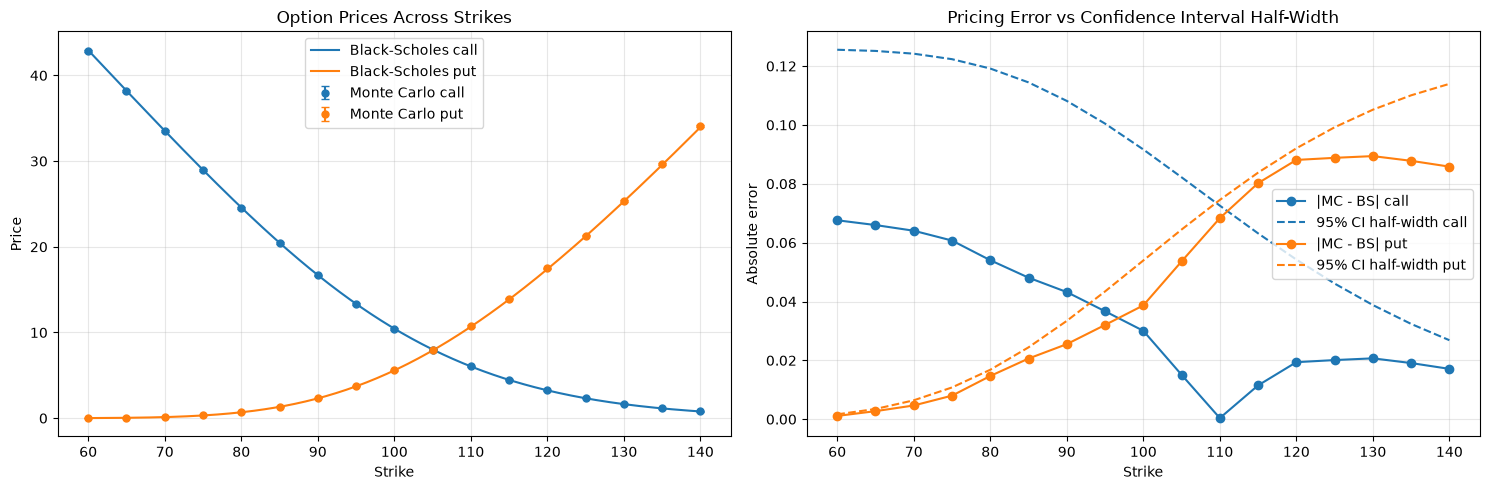

Black-Scholes price inside 95% CI for 100% of strikes


In [12]:
strike_grid = np.arange(60, 145, 5)

strike_rows = []

for strike in strike_grid:
    for option_type in ["call", "put"]:
        result = summarise_samples(
            discount_factor * european_payoff(terminal_prices, strike, option_type)
        )
        strike_rows.append({
            "strike": strike,
            "type": option_type,
            "mc_price": result.estimate,
            "half_width": result.half_width,
            "bs_price": black_scholes_price(
                initial_price, strike, risk_free_rate, annual_volatility, time_to_maturity, option_type
            ),
            "bs_inside_ci": result.contains(
                black_scholes_price(
                    initial_price, strike, risk_free_rate, annual_volatility, time_to_maturity, option_type
                )
            )
        })

strike_results = pd.DataFrame(strike_rows)
strike_results["abs_error"] = (strike_results["mc_price"] - strike_results["bs_price"]).abs()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

fine_strikes = np.linspace(strike_grid.min(), strike_grid.max(), 300)

for option_type in ["call", "put"]:
    subset = strike_results[strike_results["type"] == option_type]

    line, = axes[0].plot(
        fine_strikes,
        black_scholes_price(initial_price, fine_strikes, risk_free_rate, annual_volatility, time_to_maturity, option_type),
        linewidth=1.5,
        label=f"Black-Scholes {option_type}"
    )
    axes[0].errorbar(
        subset["strike"], subset["mc_price"], yerr=subset["half_width"],
        fmt="o", color=line.get_color(), markersize=5, capsize=3,
        label=f"Monte Carlo {option_type}"
    )

    axes[1].plot(subset["strike"], subset["abs_error"], "o-", color=line.get_color(), label=f"|MC - BS| {option_type}")
    axes[1].plot(subset["strike"], subset["half_width"], "--", color=line.get_color(), label=f"95% CI half-width {option_type}")

axes[0].set_title("Option Prices Across Strikes")
axes[0].set_xlabel("Strike")
axes[0].set_ylabel("Price")

axes[1].set_title("Pricing Error vs Confidence Interval Half-Width")
axes[1].set_xlabel("Strike")
axes[1].set_ylabel("Absolute error")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Black-Scholes price inside 95% CI for {strike_results['bs_inside_ci'].mean():.0%} of strikes")

The errors are correlated across strikes because every strike reuses the same sample. If the sample happens to have slightly too many high prices, every call is overpriced. The CI half-width is largest where the payoff varies most: for deep in-the-money options, whose payoffs are nearly linear in $S_T$.

## 4.7 The library function

`price_european_option_mc` wraps the steps above in one call. It is used in the convergence and variance-reduction notebooks.

In [13]:
library_call = price_european_option_mc(
    initial_price=initial_price,
    strike_price=strike_price,
    risk_free_rate=risk_free_rate,
    volatility=annual_volatility,
    time_to_maturity=time_to_maturity,
    n_samples=n_simulations,
    rng=rng,
    option_type="call"
)

library_call

MonteCarloEstimate(estimate=10.38309305772672, standard_error=0.04632252394473867, n_samples=100000, confidence_level=0.95)

In [14]:
assert len(terminal_prices) == n_simulations
assert np.all(terminal_prices > 0)
assert np.all(call_payoffs >= 0)
assert np.all(put_payoffs >= 0)
assert discounted_stock.contains(initial_price)
assert abs(call_mc.estimate - call_price_bs) < 4 * call_mc.standard_error
assert abs(put_mc.estimate - put_price_bs) < 4 * put_mc.standard_error
assert abs(library_call.estimate - call_price_bs) < 4 * library_call.standard_error

print("Monte Carlo option pricing checks passed.")

Monte Carlo option pricing checks passed.


## Conclusions

- Option prices are **discounted expectations under the risk-neutral measure**: simulate with drift $r$, not $\mu$.
- Monte Carlo reproduces the Black–Scholes prices for calls and puts, and its confidence intervals contain the analytical value.
- Pricing with $\mu$ gives arbitrageable prices; the real-world drift does not enter the option price.
- One simulation of $S_T$ prices every strike, but the resulting errors are correlated.

For a plain European option Black–Scholes is faster and exact. Monte Carlo matters for payoffs with no closed form: path-dependent, multi-asset, or under richer models. There the only accuracy check is the standard error. Notebook 5 tests how well it works, by measuring the error against Black–Scholes as $N$ grows.